---
title: "Waves and Fourier Transforms"
short_title: "E-M3 Waves & Fourier Transforms"
numbering:
  heading_2: true
  equation: true
---

# Waves and Fourier Transforms

:::{tip} Where this sits in the plan
Math for **electromagnetic waves** and **radiation** (E&M topics 8 and 9). Complex numbers are in mechanics M1 and M4; Fourier series in M4; partial derivatives in M3.

| Item | Stewart | Boas | Zill | Arfken |
|---|---|---|---|---|
| Complex numbers and Euler's formula | App. H | 2 | 17 | 11 |
| Fourier series and transforms | – | 7 | 12, 15 | 19, 20 |
| The wave equation | – | 13 | 12 | 9 |

Chapter numbers are approximate, as in the workbook.
:::

Exercises have separate hint and answer dropdowns.

::::{admonition} Pre-test: can you skip this notebook?
:class: dropdown

Work these without looking at the notes. Each problem names the section it tests. If **every part** is right, skip ahead to [Electromagnetic Waves](../em/08-em-waves.ipynb). If you miss a part, study just the section it names and try that problem again.

1. **The Wave Equation**

   (a) Which of these satisfy $\partial_z^2f = \dfrac{1}{v^2}\partial_t^2f$: $(z + vt)^3$, $\ z^2 - v^2t^2$, $\ z^2 + v^2t^2$?

   (b) Write $\operatorname{Re}\left[\tilde Ae^{i(kz - \omega t)}\right]$ with $\tilde A = 2e^{i\pi/3}$ as a real cosine.

2. **The Wave Equation**: spherical waves and retarded time

   (a) Why must an outgoing spherical wave have the form $f(t - r/v)/r$, with that $1/r$ factor? Think about energy.

   (b) A light signal reaches an observer 3.0 m from its source at time $t$. When was it emitted?

3. **The Fourier Transform**

   Use $F(k) = \dfrac{1}{\sqrt{2\pi}}\displaystyle\int f(z)\,e^{-ikz}\,dz$.

   (a) Find the transform of the box $f = 1$ for $|z| < a$ (and $0$ outside).

   (b) How are the transforms of $f(z - z_0)$ and $f'(z)$ related to $F(k)$?

   (c) A pulse gets narrower in $z$. What happens to its spectrum?

4. **Wave Packets and Dispersion**

   (a) For $\omega = \alpha k^2$, find the phase and group velocities.

   (b) For a free quantum particle, $\omega = \hbar k^2/2m$. Show that the group velocity is the classical velocity $p/m$.

   (c) In a medium where $\omega = ck/n$ with constant $n$, do packets spread? Why?

:::{dropdown} Answers
1. (a) $(z + vt)^3$ and $z^2 + v^2t^2$ satisfy it. $z^2 - v^2t^2$ gives $2 - (-2) = 4 \ne 0$. Note $z^2 + v^2t^2 = \tfrac12\left[(z + vt)^2 + (z - vt)^2\right]$.

   (b) $2\cos(kz - \omega t + \pi/3)$.

2. (a) The energy flux goes as $|f|^2$ and must spread over area $4\pi r^2$ while staying constant, so the amplitude falls as $1/r$.

   (b) At $t - (3.0\ \text{m})/c = t - 10$ ns.

3. (a) $F(k) = \sqrt{\dfrac{2}{\pi}}\,\dfrac{\sin ka}{k}$.

   (b) $f(z - z_0) \to e^{-ikz_0}F(k)$ and $f'(z) \to ikF(k)$.

   (c) Its spectrum broadens, since $\Delta z\,\Delta k \gtrsim 1$.

4. (a) $v_{\text{phase}} = \alpha k$ and $v_{\text{group}} = 2\alpha k$.

   (b) $v_g = d\omega/dk = \hbar k/m = p/m$.

   (c) No. $\omega \propto k$, so $v_g = v_p = c/n$ for every component and the shape travels unchanged.
:::
::::

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad, dblquad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
eps0 = 8.854e-12          # F/m
mu0 = 4e-7 * np.pi        # H/m (to 10 significant figures)
c = 2.998e8               # m/s
k_e = 1 / (4 * np.pi * eps0)

## The Wave Equation

$$
\frac{\partial^2f}{\partial z^2} = \frac{1}{v^2}\frac{\partial^2f}{\partial t^2}
$$ (eq-wave-1d)

describes a disturbance traveling at speed $v$ without changing shape. Its general solution (d'Alembert) is

$$
f(z, t) = g(z - vt) + h(z + vt) ,
$$

any shape moving right plus any shape moving left. To check, note that each term depends on $z$ and $t$ only through $z\mp vt$, so the chain rule gives $\partial_t^2 = v^2\partial_z^2$ on it.

### Sinusoidal waves and complex notation

The most important special case is

$$
f(z, t) = A\cos(kz - \omega t + \delta) = \operatorname{Re}\left[\tilde Ae^{i(kz - \omega t)}\right], \qquad \tilde A = Ae^{i\delta} ,
$$

with wavenumber $k = 2\pi/\lambda$, angular frequency $\omega = 2\pi f$, and phase velocity $v = \omega/k$. As in M4, carry the complex form through linear calculations and take the real part at the end. The complex amplitude $\tilde A$ stores the amplitude and phase together.

In three dimensions, a **plane wave** traveling in direction $\hat{k}$ is $\tilde Ae^{i(\vec{k}\cdot\vec{r} - \omega t)}$. Acting on it,

$$
\nabla\to i\vec{k}, \qquad \frac{\partial}{\partial t}\to -i\omega .
$$ (eq-plane-wave-rules)

These two substitutions turn Maxwell's equations for a plane wave into algebra: $\nabla\cdot\vec{E} = 0$ becomes $\vec{k}\cdot\vec{E} = 0$, so the wave is transverse, and so on.

### Spherical waves and retarded time

An outgoing spherical wave from a point source has the form $f = g(t - r/v)/r$. The argument $t - r/v$, the **retarded time**, says the field at distance $r$ shows what the source did a travel time earlier. The $1/r$ keeps the energy flux through each sphere constant. Radiation fields are built from exactly this.

In [2]:
# d'Alembert: any g(z - v t) solves the wave equation
z, t, v = sp.symbols("z t v", real=True)
g = sp.Function("g")
f = g(z - v * t)
display(Math(r"\frac{\partial^2 f}{\partial z^2} - \frac{1}{v^2}\frac{\partial^2 f}{\partial t^2} = " + sp.latex(sp.simplify(sp.diff(f, z, 2) - sp.diff(f, t, 2) / v**2))))
r = sp.symbols("r", positive=True)
F = g(t - r / v) / r      # spherical wave: check the radial wave equation (1/r) d^2(r F)/dr^2 = (1/v^2) d^2F/dt^2
display(Math(r"\frac{1}{r}\frac{\partial^2 (rF)}{\partial r^2} - \frac{1}{v^2}\frac{\partial^2 F}{\partial t^2} = " + sp.latex(sp.simplify(sp.diff(r * F, r, 2) / r - sp.diff(F, t, 2) / v**2))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Exercises

1. Which of these satisfy {eq}`eq-wave-1d`: (a) $e^{-(z - vt)^2}$, (b) $\sin z\cos vt$, (c) $e^{-(z^2 - v^2t^2)}$?
2. Show that $\sin z\cos vt$ is a sum of left- and right-moving waves. What kind of wave is it?

:::{dropdown} Hints
1. Check whether each is a function of $z\mp vt$, or substitute directly.
2. Use $\sin a\cos b = \tfrac12[\sin(a + b) + \sin(a - b)]$.
:::

:::{dropdown} Answers
1. (a) yes; (b) yes; (c) no.
2. $\tfrac12[\sin(z + vt) + \sin(z - vt)]$: a standing wave, made of two equal traveling waves moving in opposite directions.
:::

## The Fourier Transform

Fourier series (M4) decompose **periodic** functions into a discrete set of frequencies. For a function that is not periodic, such as a single pulse, let the period go to infinity: the frequencies become continuous and the sum becomes an integral.

:::{prf:definition} Fourier transform
:label: def-fourier-transform

$$
\tilde f(k) = \frac{1}{\sqrt{2\pi}}\int_{-\infty}^{\infty}f(z)\,e^{-ikz}\,dz, \qquad
f(z) = \frac{1}{\sqrt{2\pi}}\int_{-\infty}^{\infty}\tilde f(k)\,e^{ikz}\,dk .
$$ (eq-fourier-transform)

(Other books put the $2\pi$ factors elsewhere; only consistency matters.)
:::

$\tilde f(k)$ says how much of each spatial frequency $k$ is in $f$. The same definitions work for time and angular frequency, $f(t)\leftrightarrow\tilde f(\omega)$.

Key properties:

- **Derivatives become multiplication:** the transform of $f'$ is $ik\,\tilde f$. Linear constant-coefficient differential equations become algebraic.
- **Convolution theorem:** the transform of a convolution $\int f(z')g(z - z')\,dz'$ is $\sqrt{2\pi}\,\tilde f\,\tilde g$. A Green's-function solution (M4) is a convolution, so in Fourier space it is a product.
- **Parseval:** $\int|f|^2dz = \int|\tilde f|^2dk$. Energy can be counted in either representation.
- **Uncertainty:** a narrow function has a broad transform. For any pulse, the widths (standard deviations of $|f|^2$ and $|\tilde f|^2$) satisfy $\Delta z\,\Delta k\ge\tfrac12$, with equality for a Gaussian. Multiply by $\hbar$ and this is Heisenberg's relation.

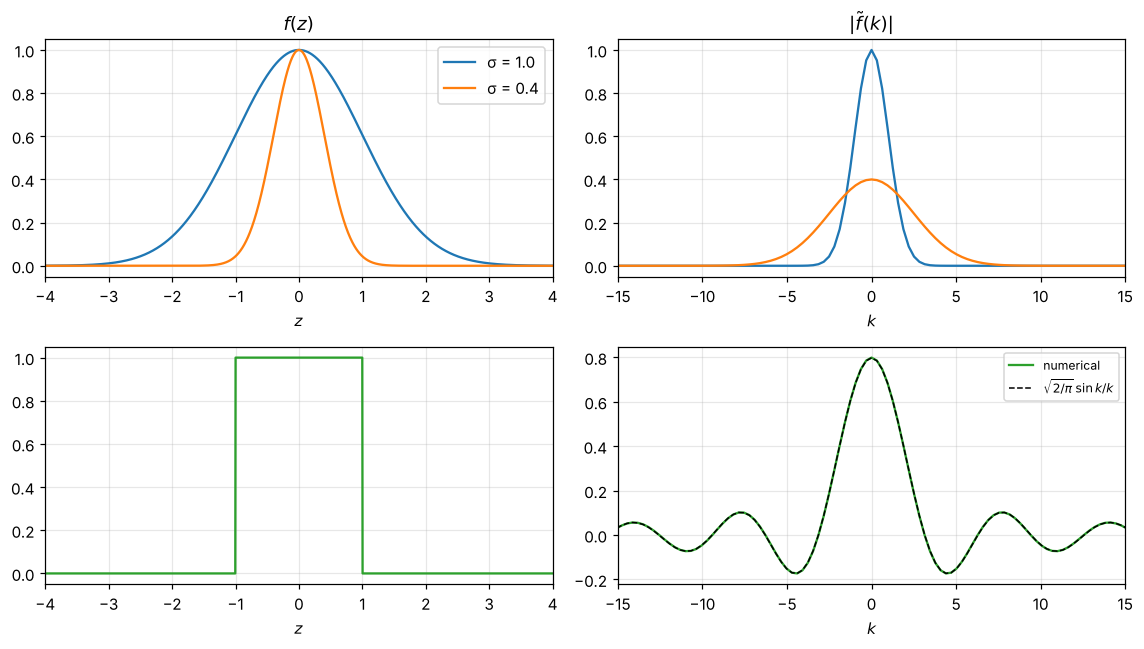

In [3]:
#| label: fig-fourier-pairs
#| caption: Fourier pairs. A Gaussian transforms to a Gaussian; narrowing it in z (orange) broadens it in k. A rectangular pulse transforms to a sinc function, whose slow 1/k falloff comes from the sharp edges.
zz = np.linspace(-10, 10, 4096)
dz = zz[1] - zz[0]
kk = np.fft.fftshift(np.fft.fftfreq(zz.size, d=dz)) * 2 * np.pi

def ft(fz):   # numerical version of eq-fourier-transform (phase factor for the grid offset included)
    F = np.fft.fftshift(np.fft.fft(np.fft.ifftshift(fz))) * dz / np.sqrt(2 * np.pi)
    return F

fig, axes = plt.subplots(2, 2, figsize=(10.5, 6))
for s_, col in [(1.0, "tab:blue"), (0.4, "tab:orange")]:
    fz = np.exp(-zz**2 / (2 * s_**2))
    axes[0, 0].plot(zz, fz, color=col, label=f"σ = {s_}")
    axes[0, 1].plot(kk, np.abs(ft(fz)), color=col)
box = (np.abs(zz) < 1).astype(float)
axes[1, 0].plot(zz, box, color="tab:green")
axes[1, 1].plot(kk, ft(box).real, color="tab:green", label="numerical")
axes[1, 1].plot(kk, np.sqrt(2 / np.pi) * np.sinc(kk / np.pi), "k--", lw=1, label=r"$\sqrt{2/\pi}\,\sin k/k$")
axes[0, 0].legend(); axes[1, 1].legend(fontsize=8)
for ax in axes[:, 0]: ax.set_xlim(-4, 4); ax.set_xlabel("$z$")
for ax in axes[:, 1]: ax.set_xlim(-15, 15); ax.set_xlabel("$k$")
axes[0, 0].set_title("$f(z)$"); axes[0, 1].set_title(r"$|\tilde f(k)|$")
plt.tight_layout(); plt.show()

In [4]:
z, k = sp.symbols("z k", real=True)
s = sp.symbols("sigma", positive=True)
ftg = sp.integrate(sp.exp(-z**2 / (2 * s**2)) * sp.exp(-sp.I * k * z), (z, -sp.oo, sp.oo)) / sp.sqrt(2 * sp.pi)
display(Math(r"\tilde f_{\text{Gaussian}}(k) = " + sp.latex(sp.simplify(ftg))))
ftb = sp.integrate(sp.exp(-sp.I * k * z), (z, -1, 1)) / sp.sqrt(2 * sp.pi)
display(Math(r"\tilde f_{\text{box}}(k) = " + sp.latex(sp.simplify(ftb.rewrite(sp.sin)))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Wave Packets and Dispersion

Build a pulse by superposing plane waves,

$$
f(z, t) = \frac{1}{\sqrt{2\pi}}\int\tilde A(k)\,e^{i(kz - \omega(k)t)}\,dk .
$$

The function $\omega(k)$, the **dispersion relation**, decides what happens. If $\omega = vk$ exactly, every component moves at the same speed and the pulse keeps its shape. In a medium (glass, a plasma, a waveguide) $\omega(k)$ is not linear, and two speeds appear:

$$
v_{\text{phase}} = \frac{\omega}{k}, \qquad v_{\text{group}} = \frac{d\omega}{dk} .
$$ (eq-group-velocity)

For a packet concentrated near $k_0$, expand $\omega(k)\approx\omega_0 + v_g(k - k_0)$: the envelope moves at $v_g$, while the crests inside it move at $v_{\text{phase}}$. The next term in the expansion, $\tfrac12\omega''(k_0)(k - k_0)^2$, makes the packet spread. Energy and information travel at the group velocity.

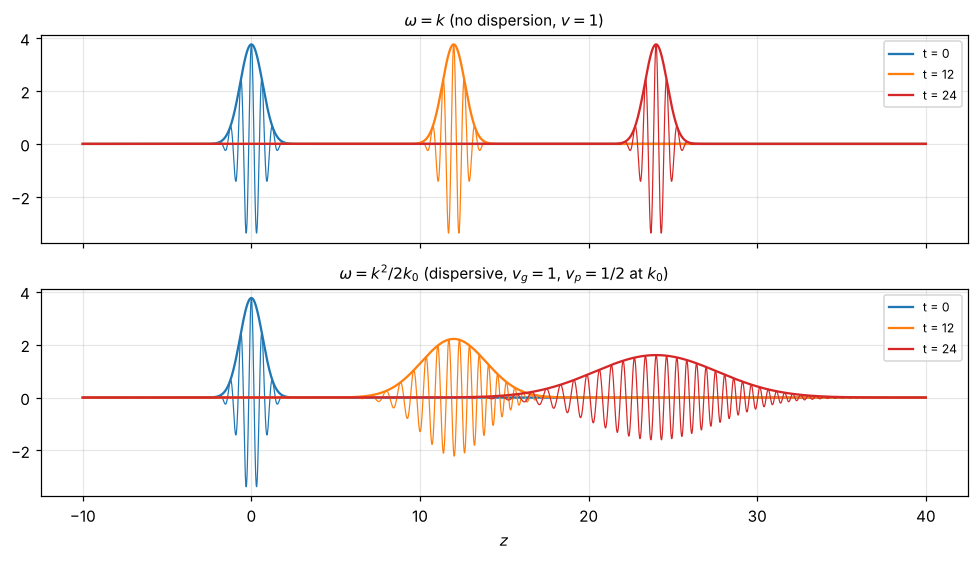

In [5]:
#| label: fig-dispersion
#| caption: "A Gaussian packet (k₀ = 10) at t = 0, 12, 24. Top, no dispersion (ω = k): it moves rigidly at speed 1. Bottom, ω = k²/2k₀: the envelope still moves at the group velocity 1, the crests inside it move at the phase velocity 1/2, and the packet spreads."
zz = np.linspace(-10, 40, 4000)
k = np.linspace(0, 20, 2001); dk = k[1] - k[0]
k0, sk = 10.0, 1.5
A = np.exp(-(k - k0)**2 / (2 * sk**2))
fig, axes = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True)
for ax, wfun, title in [(axes[0], lambda kk: kk, r"$\omega = k$ (no dispersion, $v = 1$)"),
                        (axes[1], lambda kk: kk**2 / (2 * k0), r"$\omega = k^2/2k_0$ (dispersive, $v_g = 1$, $v_p = 1/2$ at $k_0$)")]:
    for tt, col in [(0, "tab:blue"), (12, "tab:orange"), (24, "tab:red")]:
        f = (A[None, :] * np.exp(1j * (k[None, :] * zz[:, None] - wfun(k)[None, :] * tt))).sum(axis=1) * dk
        ax.plot(zz, f.real, color=col, lw=0.8)
        ax.plot(zz, np.abs(f), color=col, lw=1.5, label=f"t = {tt}")
    ax.set_title(title, fontsize=10); ax.legend(fontsize=8, loc="upper right")
axes[1].set_xlabel("$z$"); plt.tight_layout(); plt.show()

### Exercises

1. Find the Fourier transform of $f(z) = e^{-a|z|}$ ($a > 0$).
2. For deep-water waves, $\omega = \sqrt{gk}$. Show that the group velocity is half the phase velocity.
3. A plasma has $\omega^2 = \omega_p^2 + c^2k^2$. Find $v_{\text{phase}}$ and $v_{\text{group}}$ and show that $v_{\text{phase}}v_{\text{group}} = c^2$. Which one exceeds $c$, and why is that not a problem?

:::{dropdown} Hints
1. Split the integral at $z = 0$.
2. Differentiate $\sqrt{gk}$.
3. $v_g = d\omega/dk = c^2k/\omega$.
:::

:::{dropdown} Answers
1. $\tilde f(k) = \sqrt{\dfrac2\pi}\,\dfrac{a}{a^2 + k^2}$ (a Lorentzian).
2. $v_g = \tfrac12\sqrt{g/k} = \tfrac12v_p$.
3. $v_p = \omega/k > c$ and $v_g = c^2k/\omega < c$, with $v_pv_g = c^2$. The phase velocity carries no energy or information, so exceeding $c$ violates nothing.
:::

## Summary

- The wave equation's solutions are shapes traveling at $\pm v$; sinusoids are its building blocks, handled in complex form.
- For plane waves $\nabla\to i\vec{k}$ and $\partial_t\to -i\omega$, turning field equations into algebra.
- Outgoing spherical waves are functions of retarded time $t - r/v$, divided by $r$.
- The Fourier transform decomposes any pulse into plane waves; derivatives become multiplication, convolutions become products, and narrow pulses have broad spectra.
- In a dispersive medium, envelopes move at $d\omega/dk$ and crests at $\omega/k$; packets spread.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.